# 04 - Método da bisseção
Vamos aprender sobre como usar o método da bisseção para encontrar as raízes de funções reais.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana4
```

Faça o checkout nessa nova branch:

```bash
git checkout semana4
```

A partir desta atividade, os arquivos de algoritmos ficarão dentro da pasta utils.

```txt
├─ utils/
│   └─ __init__.py
│   └─ algoritmos.py
```

<hr />

## Atividade 1
Escreva o método da bisseção dentro do arquivo $utils/algoritmos.py$.

In [ ]:
def bissecao(f,     # função que queremos encontrar a raiz
              a,    # a início do intervalo
              b,    # b fim do intervalo
              TOL,   # erro tolerado
              iter=16):  # número máximo de iterações
    c = (a + b) / 2  # ponto médio entre os valores a e b
    if f(a) * f(b) > 0:
        raise ValueError("Nenhuma raiz encontrada no intervalo.")
    else:
        i = 0  # variável contador
        ERRO = abs(f(b) - f(a))  # diferença entre os valores de y

        while ERRO > TOL and i < iter:  # loop iterativo com parada
            c = (a + b) / 2.0
            if f(c) == 0:
                return c, i
            elif f(a) * f(c) < 0:
                b = c
            else:
                a = c
            i += 1
            ERRO = abs(f(b) - f(a))
        return c, i

Importe e teste a função:  

$$
f(x) = x^3 - x - 2
$$

Em que os valores iniciais a e b são obtidos graficamente.

In [3]:
%pip install numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 33.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 39.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 38.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 30.6 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib]8 [matplotlib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


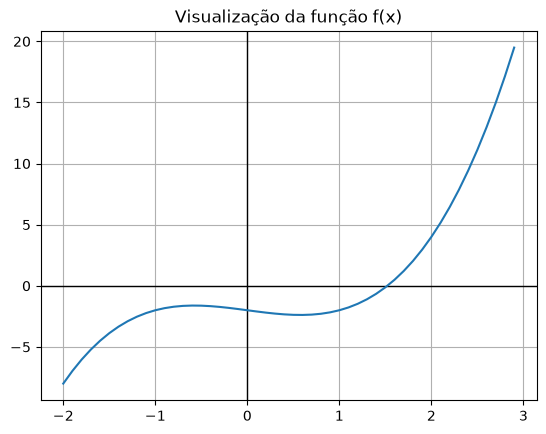

raiz = 1.5213775634765625 , i = 16


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
import os

# Sobe um nível para a raiz do projeto e adiciona ao caminho do sistema
sys.path.append(os.path.abspath(os.path.join('..')))

# Agora você importa suas ferramentas da pasta utils
from utils.algoritmos import bissecao

# Definição da função
def f(x):
    return x**3 - x - 2

def plot(f, number=1):
    # Intervalo para plotar
    x_vals = np.arange(-2, 3, 0.1)
    y_vals = f(x_vals)

    plt.axhline(0, color="black", linewidth=1)  # eixo x
    plt.axvline(0, color="black", linewidth=1)  # eixo y
    plt.plot(x_vals, y_vals)
    plt.grid(True)
    plt.title("Visualização da função f(x)")
    plt.show()
    plt.close()

def main():
    plot(f, 1)
    r, i = bissecao(f, 1, 2, 1e-15)
    print(f"raiz = {r} , i = {i}")

if __name__ == "__main__":
    main()

## Atividade 2
Considere a equação  

$$
\sqrt{x} = \cos(x).
$$  

Use o método da bisseção com intervalo inicial obtido por gráfico (entre 0 e 1) para calcular um valor aproximado com precisão de $10^{-4}$ para no máximo 4 iterações.

**Resposta:**  
$
x \approx 0.6875
$ 

In [1]:
import math


def f(x_value: float) -> float:
    return math.sqrt(x_value) - math.cos(x_value)


a = 0.0
b = 1.0
max_iterations = 4

if f(a) * f(b) > 0:
    raise ValueError("O intervalo inicial não contém uma troca de sinal.")

for iteration in range(max_iterations):
    midpoint = (a + b) / 2
    if f(a) * f(midpoint) <= 0:
        b = midpoint
    else:
        a = midpoint

print(f"Aproximação após {max_iterations} iterações: x ≈ {midpoint:.4f}")
print(f"Intervalo final: [{a:.4f}, {b:.4f}] (largura {b - a:.4f})")
print("A tolerância de 1e-4 não é atingida com apenas 4 iterações.")

assert midpoint == 0.6875
assert math.isclose(b - a, 1 / 16)

Aproximação após 4 iterações: x ≈ 0.6875
Intervalo final: [0.6250, 0.6875] (largura 0.0625)
A tolerância de 1e-4 não é atingida com apenas 4 iterações.


## Atividade 3
Trace o gráfico e isole as três primeiras raízes positivas da função:  

$$
f(x) = 5\sin(x^2) - \exp\!\left(\frac{x}{10}\right)
$$  

em intervalos de comprimento $(0.1)$. Então, use o método da bisseção para obter aproximações dos zeros com precisão de $10^{-5}$.  

**Resposta:**  

- Intervalo $(0.4, 0.5)$, zero em $(x \approx 0.45931)$.  
- Intervalo $(1.7, 1.8)$, zero em $(x \approx 1.7036)$.  
- Intervalo $(2.5, 2.6)$, zero em $(x \approx 2.5582)$. 

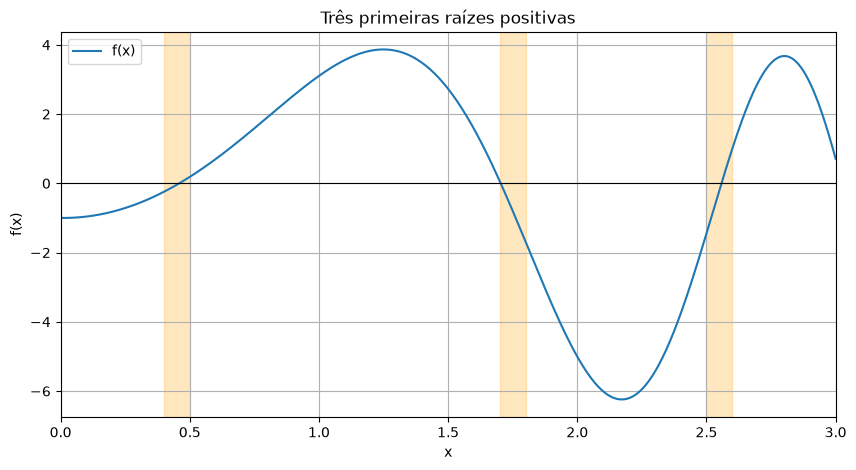

Intervalos isoladores e raízes aproximadas:
[0.4, 0.5]: x ≈ 0.45930786, iterações=13, erro máximo ≤ 6.10e-06
[1.7, 1.8]: x ≈ 1.70357056, iterações=13, erro máximo ≤ 6.10e-06
[2.5, 2.6]: x ≈ 2.55820923, iterações=13, erro máximo ≤ 6.10e-06


In [5]:
import math
import matplotlib.pyplot as plt


def f(x_value: float) -> float:
    return 5 * math.sin(x_value * x_value) - math.exp(x_value / 10)


def bissection(function, left: float, right: float, tolerance: float):
    value_left = function(left)
    value_right = function(right)
    if value_left * value_right > 0:
        raise ValueError("O intervalo não contém uma troca de sinal.")

    iterations = 0
    while (right - left) / 2 > tolerance:
        midpoint = (left + right) / 2
        value_midpoint = function(midpoint)

        if value_midpoint == 0:
            return midpoint, iterations + 1, midpoint, midpoint
        if value_left * value_midpoint < 0:
            right = midpoint
            value_right = value_midpoint
        else:
            left = midpoint
            value_left = value_midpoint
        iterations += 1

    midpoint = (left + right) / 2
    return midpoint, iterations, left, right


brackets = []
left = 0.0
value_left = f(left)

for index in range(1, 31):
    right = index / 10
    value_right = f(right)
    if value_left * value_right < 0:
        brackets.append((left, right))
        if len(brackets) == 3:
            break
    left = right
    value_left = value_right

if len(brackets) < 3:
    raise RuntimeError("Não foram encontrados três intervalos com troca de sinal.")

x_values = [index / 200 for index in range(601)]
y_values = [f(x_value) for x_value in x_values]
plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values, label="f(x)")
plt.axhline(0, color="black", linewidth=0.8)
for interval_left, interval_right in brackets:
    plt.axvspan(interval_left, interval_right, color="orange", alpha=0.25)
plt.xlim(0, 3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Três primeiras raízes positivas")
plt.grid(True)
plt.legend()
plt.show()
plt.close()

print("Intervalos isoladores e raízes aproximadas:")
for interval_left, interval_right in brackets:
    root, iterations, final_left, final_right = bissection(
        f, interval_left, interval_right, tolerance=1e-5
    )
    print(
        f"[{interval_left:.1f}, {interval_right:.1f}]: "
        f"x ≈ {root:.8f}, iterações={iterations}, "
        f"erro máximo ≤ {(final_right - final_left) / 2:.2e}"
    )

## Atividade 4
O desenho abaixo mostra um circuito não linear envolvendo uma fonte de tensão constante, um diodo retificador e um resistor.  

Sabendo que a relação entre a corrente ($I_d$) e a tensão ($v_d$) no diodo é dada pela seguinte expressão:

$ I_d = I_R \left( \exp\left(\tfrac{v_d}{v_t}\right) - 1 \right) $

onde $I_R$ é a corrente de condução reversa e $v_t$ a tensão térmica, dada por  

$ v_t = \tfrac{kT}{q} $

com $k$ a constante de Boltzmann, $T$ a temperatura de operação e $q$ a carga do elétron.  

Aqui, $I_R = 1\,pA = 10^{-12}\,A$, $T = 300\,K$.  

Escreva o problema como uma equação na incógnita $v_d$, usando o método da bisseção, e resolva-o com **3 algarismos significativos** para os seguintes casos:

- $V = 30 \, V$ e $R = 1 \, k\Omega$  
- $V = 3 \, V$ e $R = 1 \, k\Omega$  
- $V = 3 \, V$ e $R = 10 \, k\Omega$  
- $V = 300 \, mV$ e $R = 1 \, k\Omega$  
- $V = -300 \, mV$ e $R = 1 \, k\Omega$  
- $V = -30 \, V$ e $R = 1 \, k\Omega$  
- $V = -30 \, V$ e $R = 10 \, k\Omega$  

![Circuito](https://www.ufrgs.br/reamat/CalculoNumerico/livro-py/main4x.png)

**Dica:**  
A equação do circuito é:

$ V = R I_d + v_d $

**Resposta:**  
a) $0.623$  
b) $0.559$  
c) $0.500$  
d) $0.300$  
e) $-0.300$  
f) $-30$  
g) $-30$

In [7]:
import math


BOLTZMANN_CONSTANT = 1.380649e-23
ELEMENTARY_CHARGE = 1.602176634e-19
TEMPERATURE = 300.0
REVERSE_CURRENT = 1e-12
THERMAL_VOLTAGE = BOLTZMANN_CONSTANT * TEMPERATURE / ELEMENTARY_CHARGE


def circuit_equation(diode_voltage: float, source_voltage: float, resistance: float) -> float:
    diode_current = REVERSE_CURRENT * math.expm1(diode_voltage / THERMAL_VOLTAGE)
    return resistance * diode_current + diode_voltage - source_voltage


def solve_diode_voltage(source_voltage: float, resistance: float) -> tuple[float, int]:
    if source_voltage > 0:
        left = 0.0
        right = min(source_voltage, 1.0)
    elif source_voltage < 0:
        left = source_voltage
        right = 0.0
    else:
        return 0.0, 0

    value_left = circuit_equation(left, source_voltage, resistance)
    value_right = circuit_equation(right, source_voltage, resistance)
    if value_left * value_right > 0:
        raise ValueError("O intervalo inicial não contém uma troca de sinal.")

    for iteration in range(1, 201):
        midpoint = (left + right) / 2
        value_midpoint = circuit_equation(midpoint, source_voltage, resistance)

        if value_midpoint == 0:
            return float(format(midpoint, ".3g")), iteration
        if value_left * value_midpoint < 0:
            right = midpoint
            value_right = value_midpoint
        else:
            left = midpoint
            value_left = value_midpoint

        if format(left, ".3g") == format(right, ".3g"):
            return float(format((left + right) / 2, ".3g")), iteration

    raise RuntimeError("A bisseção não convergiu para 3 algarismos significativos.")


def format_significant(value: float, digits: int = 3) -> str:
    if value == 0.0:
        return f"{value:.{digits - 1}f}"

    decimal_places = digits - 1 - math.floor(math.log10(abs(value)))
    return f"{value:.{max(decimal_places, 0)}f}"


cases = [
    ("a", 30.0, 1e3),
    ("b", 3.0, 1e3),
    ("c", 3.0, 10e3),
    ("d", 0.3, 1e3),
    ("e", -0.3, 1e3),
    ("f", -30.0, 1e3),
    ("g", -30.0, 10e3),
]
expected_results = [0.623, 0.559, 0.500, 0.300, -0.300, -30.0, -30.0]

print(f"Tensão térmica: v_t = {THERMAL_VOLTAGE:.6f} V")
for (label, source_voltage, resistance), expected in zip(cases, expected_results):
    diode_voltage, iterations = solve_diode_voltage(source_voltage, resistance)
    assert diode_voltage == expected
    print(
        f"{label}) V={source_voltage:g} V, R={resistance / 1000:g} kΩ: "
        f"v_d={format_significant(diode_voltage)} V ({iterations} iterações)"
    )

Tensão térmica: v_t = 0.025852 V
a) V=30 V, R=1 kΩ: v_d=0.623 V (12 iterações)
b) V=3 V, R=1 kΩ: v_d=0.559 V (11 iterações)
c) V=3 V, R=10 kΩ: v_d=0.500 V (11 iterações)
d) V=0.3 V, R=1 kΩ: v_d=0.300 V (10 iterações)
e) V=-0.3 V, R=1 kΩ: v_d=-0.300 V (10 iterações)
f) V=-30 V, R=1 kΩ: v_d=-30.0 V (10 iterações)
g) V=-30 V, R=10 kΩ: v_d=-30.0 V (10 iterações)


## Atividade 5
Calcule o comprimento do cabo ($C$) entre duas torres de transmissão (i.e., a catenária).  

A distância entre as torres é de $d = 500 \, m$.  

A flecha máxima permitida é $f_{max} = 50 \, m$.  

Flecha é a distância vertical entre uma reta que liga os dois pontos de fixação.  

A flecha ($f$) depende do comprimento do vão ($d$) e da tração ($C$) aplicada ao cabo.  

O seu modelo matemático pode ser:

$ f = C \left[ \cosh\left(\tfrac{d}{2C}\right) - 1 \right] \quad $

**Resposta:** $633.1621 \, m$

In [8]:
import math


SPAN = 500.0
MAXIMUM_SAG = 50.0


def sag(catenary_parameter: float) -> float:
    if catenary_parameter <= 0.0:
        raise ValueError("C deve ser positivo.")

    half_argument = SPAN / (4.0 * catenary_parameter)
    return 2.0 * catenary_parameter * math.sinh(half_argument) ** 2


def equation(catenary_parameter: float) -> float:
    return sag(catenary_parameter) - MAXIMUM_SAG


def bisection(left: float, right: float, tolerance: float = 1e-8) -> tuple[float, int]:
    value_left = equation(left)
    value_right = equation(right)
    if value_left * value_right > 0.0:
        raise ValueError("O intervalo não contém uma troca de sinal.")

    iterations = 0
    while (right - left) / 2.0 > tolerance:
        midpoint = (left + right) / 2.0
        value_midpoint = equation(midpoint)

        if value_midpoint == 0.0:
            return midpoint, iterations + 1
        if value_left * value_midpoint < 0.0:
            right = midpoint
        else:
            left = midpoint
            value_left = value_midpoint
        iterations += 1

    return (left + right) / 2.0, iterations


catenary_parameter, iterations = bisection(SPAN, 2.0 * SPAN)
calculated_sag = sag(catenary_parameter)
assert abs(calculated_sag - MAXIMUM_SAG) < 1e-7
assert abs(catenary_parameter - 633.1621) < 1e-3

print(f"C ≈ {catenary_parameter:.4f} m")
print(f"Flecha calculada ≈ {calculated_sag:.8f} m")
print(f"Iterações: {iterations}")

C ≈ 633.1622 m
Flecha calculada ≈ 50.00000000 m
Iterações: 35


## Atividade 6
Um retificador de meia onda a diodo alimenta uma carga indutiva-resistiva ($f = 1 \, kHz$, $L = 100 \, mH$ e $R = 1 \, k\Omega$).  

Encontre o ângulo $\beta$ para o qual a corrente $I_d$ no diodo se anula.  

Considere o seguinte modelo matemático:

$ I_d = \sin(\beta - \phi) + \sin(\phi)e^{-\tfrac{\beta}{\tan(\phi)}} \quad $

com  

$ \tan(\phi) = \tfrac{2\pi f L}{R} $

**Resposta:** $\beta = 212.2284^\circ$

In [12]:
import math


FREQUENCY = 1_000.0
INDUCTANCE = 0.1
RESISTANCE = 1_000.0
TANGENT_PHI = 2.0 * math.pi * FREQUENCY * INDUCTANCE / RESISTANCE
PHI = math.atan(TANGENT_PHI)


def diode_current(beta: float) -> float:
    return math.sin(beta - PHI) + math.sin(PHI) * math.exp(-beta / TANGENT_PHI)


def bisection(function, left: float, right: float, tolerance: float = 1e-12):
    value_left = function(left)
    value_right = function(right)
    if value_left * value_right > 0.0:
        raise ValueError("O intervalo não contém uma troca de sinal.")

    iterations = 0
    while (right - left) / 2.0 > tolerance:
        midpoint = (left + right) / 2.0
        value_midpoint = function(midpoint)

        if value_midpoint == 0.0:
            return midpoint, iterations + 1
        if value_left * value_midpoint < 0.0:
            right = midpoint
        else:
            left = midpoint
            value_left = value_midpoint
        iterations += 1

    return (left + right) / 2.0, iterations


beta_radians, iterations = bisection(diode_current, math.pi, 2.0 * math.pi)
beta_degrees = math.degrees(beta_radians)
reference_degrees = 212.2284
reference_residual = diode_current(math.radians(reference_degrees))
assert abs(diode_current(beta_radians)) < 1e-12

print(f"tan(phi) = {TANGENT_PHI:.8f}")
print(f"phi = {math.degrees(PHI):.4f}°")
print(f"Raiz da equação: beta = {beta_degrees:.4f}° ({beta_radians:.8f} rad)")
print(f"I_d(beta) = {diode_current(beta_radians):.3e}; iterações = {iterations}")
print(
    f"O valor 212.2284° do enunciado produz I_d = "
    f"{reference_residual:.3e}, portanto não é a raiz exata deste modelo."
)

tan(phi) = 0.62831853
phi = 32.1419°
Raiz da equação: beta = 212.2258° (3.70403927 rad)
I_d(beta) = 6.329e-13; iterações = 41
O valor 212.2284° do enunciado produz I_d = -4.518e-05, portanto não é a raiz exata deste modelo.


## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 4"
git push origin semana4
```